In [1]:
# ============ 셀 1: 설정 (L7: full 스펙트럼 ρ 0.05 + decay ρ 0.1, 사전학습 → 파인튜닝) ============
import os, json, time, math, random, glob, shutil
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.nn.attention import sdpa_kernel, SDPBackend

assert torch.cuda.is_available(), "GPU가 꺼져 있어요. Settings → Accelerator → GPU T4 로 바꾸세요."
DEV = 'cuda'

OUT  = '/kaggle/working/exp_l7'
DATA = '/tmp/llm_data'
os.makedirs(OUT, exist_ok=True); os.makedirs(DATA, exist_ok=True)

CFG = dict(
    seed=0, ctx=256, vocab=50304,
    d_model=512, n_layer=6, n_head=8,
    # 사전학습: L5A·L6A와 동일
    pre_epochs=10, pre_bs=32, pre_wd=0.1, warmup_frac=0.02, decay_frac=0.2, grad_clip=1.0,
    muon_lr=0.005, adam_lr_aux=1e-3, muon_momentum=0.95, ns_steps=5, ns_inner=5,
    decay_rho_new=0.1,        # decay 20% 구간의 새 ρ
    full_rho_new=0.05,        # full 스펙트럼의 새 ρ (decay ρ 0.05와 공정 비교)
    # 파인튜닝: L5B·L6B와 동일
    ft_muon_div=[10, 3], ft_adam_lrs=[1e-4, 1e-3 / 3],
    ft_steps=1000, ft_bs=32, ft_wd=0.1, ft_warmup=50, ft_seeds=[0, 1, 2], ft_eval_every=100,
    code_files=10000, code_max_chars=20000,
    # 평가·측정
    eval_seqs=400, eval_bs=32, hvp_iters=20, gap_euc_rho=0.05, gap_spec_rho=2e-3,
)
json.dump(CFG, open(f'{OUT}/config.json', 'w'), indent=2)

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def find_input(folder, name):
    hits = glob.glob(f'/kaggle/input/**/{folder}/{name}', recursive=True)
    assert hits, f"{folder}/{name}을 못 찾았어요. Add Input에서 해당 노트북을 추가했는지 확인하세요."
    return hits[0]

print('GPU :', torch.cuda.get_device_name(0), '| torch', torch.__version__)
for f in ['exp_l6_pretrain/pre_shared_80.pt', 'exp_l6_pretrain/pre_off_repro.pt',
          'exp_l6_finetune/efficiency.csv', 'exp_l5_finetune/efficiency.csv']:
    print('  입력 확인:', f, '→', '있음' if glob.glob(f'/kaggle/input/**/{f}', recursive=True) else '없음 ← Add Input 확인')

GPU : Tesla T4 | torch 2.11.0+cu128
  입력 확인: exp_l6_pretrain/pre_shared_80.pt → 있음
  입력 확인: exp_l6_pretrain/pre_off_repro.pt → 있음
  입력 확인: exp_l6_finetune/efficiency.csv → 있음
  입력 확인: exp_l5_finetune/efficiency.csv → 있음


In [2]:
# ============ 셀 2: BabyLM + 파이썬 코드 다운로드, 토큰화 (이전 실험들과 같은 방식) ============
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained('gpt2'); tok.model_max_length = int(1e9)
EOS = tok.eos_token_id

def encode_texts(texts, bs=256):
    parts = []
    for i in range(0, len(texts), bs):
        for ids in tok(texts[i:i + bs])['input_ids']:
            parts.append(np.array(ids + [EOS], dtype=np.uint16))
    return np.concatenate(parts)

def chunk_lines(text, n=200):
    lines = text.split('\n')
    return ['\n'.join(lines[i:i + n]) for i in range(0, len(lines), n)]

# ---------- BabyLM ----------
if os.path.exists(f'{DATA}/babylm_val.npy'):
    print('BabyLM 토큰 파일이 이미 있음 → 건너뜀')
else:
    try:
        from huggingface_hub import snapshot_download
        root = snapshot_download('cambridge-climb/BabyLM', repo_type='dataset', allow_patterns=['10M/*', 'dev/*'])
        tr_files = sorted(f for f in glob.glob(f'{root}/10M/*') if os.path.isfile(f))
        dv_files = sorted(f for f in glob.glob(f'{root}/dev/*') if os.path.isfile(f))
        assert tr_files and dv_files, '파일 없음'
        tr_texts, dv_texts = [], []
        for f in tr_files: tr_texts += chunk_lines(open(f, encoding='utf-8', errors='ignore').read())
        for f in dv_files: dv_texts += chunk_lines(open(f, encoding='utf-8', errors='ignore').read()[:500_000])
        src = 'cambridge-climb/BabyLM (2023)'
    except Exception as e:
        print('2023판 다운로드 실패 → 2026판으로 대체:', repr(e)[:200])
        from datasets import load_dataset
        ds = load_dataset('BabyLM-community/BabyLM-2026-Strict-Small', split='train')
        col = [c for c, t in ds.features.items() if getattr(t, 'dtype', None) == 'string'][0]
        lines = [t for t in ds[col] if t and t.strip()]
        idx = np.random.RandomState(0).permutation(len(lines)); nv = len(lines) // 20
        dv_lines = [lines[i] for i in idx[:nv]]; tr_lines = [lines[i] for i in idx[nv:]]
        tr_texts = ['\n'.join(tr_lines[i:i + 200]) for i in range(0, len(tr_lines), 200)]
        dv_texts = ['\n'.join(dv_lines[i:i + 200]) for i in range(0, len(dv_lines), 200)]
        src = 'BabyLM-community/BabyLM-2026-Strict-Small (5%를 검증용으로 분리)'
    print('BabyLM 출처:', src, flush=True)
    tr = encode_texts(tr_texts); dv = encode_texts(dv_texts)
    np.save(f'{DATA}/babylm_train.npy', tr); np.save(f'{DATA}/babylm_val.npy', dv)
    print(f'BabyLM 토큰: train {len(tr)/1e6:.1f}M, val {len(dv)/1e6:.1f}M   (기존: 15.7M / 0.8M)')

# ---------- 파이썬 코드 ----------
if os.path.exists(f'{DATA}/code_val.npy'):
    print('코드 토큰 파일이 이미 있음 → 건너뜀')
else:
    from datasets import load_dataset
    try:
        ds = load_dataset('bigcode/the-stack-smol', data_dir='data/python', split='train')
        src = 'bigcode/the-stack-smol (python)'
    except Exception as e:
        print('the-stack-smol 실패 → codeparrot으로 대체:', repr(e)[:200])
        ds = load_dataset('codeparrot/codeparrot-clean-valid', split='train')
        src = 'codeparrot/codeparrot-clean-valid'
    n = min(CFG['code_files'], len(ds))
    ds = ds.shuffle(seed=0).select(range(n))
    files = [c[:CFG['code_max_chars']] for c in ds['content']]
    nv = n // 10
    cv = encode_texts(files[:nv]); ct = encode_texts(files[nv:])
    np.save(f'{DATA}/code_train.npy', ct); np.save(f'{DATA}/code_val.npy', cv)
    print(f'코드 출처: {src} | 토큰: train {len(ct)/1e6:.1f}M, val {len(cv)/1e6:.1f}M   (기존: 26.9M / 3.0M)')

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

Repo card metadata block was not found. Setting CardData to empty.


file-000000000054.json.gz: reconstructing file:   0%|          |  0.00B /  142MB            

file-000000000054.json.gz: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/61373 [00:00<?, ? examples/s]

코드 출처: codeparrot/codeparrot-clean-valid | 토큰: train 26.9M, val 3.0M   (기존: 26.9M / 3.0M)


In [3]:
# ============ 셀 3: 모델, Muon, SAM(유클리드/스펙트럼), 사전학습·파인튜닝·측정 도구 ============
def load_tokens(name):
    return torch.from_numpy(np.load(f'{DATA}/{name}.npy').astype(np.int64)).to(DEV)

TR_BABY, VA_BABY = load_tokens('babylm_train'), load_tokens('babylm_val')
TR_CODE, VA_CODE = load_tokens('code_train'), load_tokens('code_val')

class Stream:
    def __init__(self, tokens, bs, ctx=CFG['ctx']):
        n = (len(tokens) - 1) // ctx
        self.chunks = tokens[:n * ctx + 1].unfold(0, ctx + 1, ctx)
        self.n, self.bs, self.spe = n, bs, n // bs
        self._key = None
    def batch(self, step, seed):
        ep, i = divmod(step, self.spe)
        if self._key != (seed, ep):
            g = torch.Generator().manual_seed(seed * 100003 + ep)
            self._perm = torch.randperm(self.n, generator=g).to(DEV); self._key = (seed, ep)
        b = self.chunks[self._perm[i * self.bs:(i + 1) * self.bs]]
        return b[:, :-1], b[:, 1:]

def make_eval(tokens, n, seed, ctx=CFG['ctx']):
    starts = np.random.RandomState(seed).randint(0, len(tokens) - ctx - 1, size=n)
    idx = torch.from_numpy(starts).to(DEV)[:, None] + torch.arange(ctx + 1, device=DEV)
    b = tokens[idx]
    return b[:, :-1], b[:, 1:]

EV_BABY = make_eval(VA_BABY, CFG['eval_seqs'], seed=11)
EV_CODE = make_eval(VA_CODE, CFG['eval_seqs'], seed=12)

class Block(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        self.h = h
        self.ln1 = nn.LayerNorm(d); self.qkv = nn.Linear(d, 3 * d); self.proj = nn.Linear(d, d)
        self.ln2 = nn.LayerNorm(d); self.fc = nn.Linear(d, 4 * d); self.fc2 = nn.Linear(4 * d, d)
    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(self.ln1(x)).split(C, dim=2)
        q, k, v = [t.view(B, T, self.h, C // self.h).transpose(1, 2) for t in (q, k, v)]
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        x = x + self.proj(y.transpose(1, 2).contiguous().view(B, T, C))
        return x + self.fc2(F.gelu(self.fc(self.ln2(x))))

class GPT(nn.Module):
    def __init__(self, V=CFG['vocab'], d=CFG['d_model'], L=CFG['n_layer'], h=CFG['n_head'], T=CFG['ctx']):
        super().__init__()
        self.wte = nn.Embedding(V, d); self.wpe = nn.Embedding(T, d)
        self.blocks = nn.ModuleList([Block(d, h) for _ in range(L)])
        self.lnf = nn.LayerNorm(d)
        for n, p in self.named_parameters():
            if p.ndim >= 2:
                std = 0.02 / math.sqrt(2 * L) if n.endswith(('proj.weight', 'fc2.weight')) else 0.02
                nn.init.normal_(p, 0.0, std)
            elif n.endswith('bias'):
                nn.init.zeros_(p)
    def forward(self, idx, targets):
        x = self.wte(idx) + self.wpe(torch.arange(idx.shape[1], device=idx.device))
        for b in self.blocks:
            x = b(x)
        logits = F.linear(self.lnf(x), self.wte.weight)
        return F.cross_entropy(logits.view(-1, logits.size(-1)), targets.reshape(-1))

def make_model():
    return GPT().to(DEV)

def newton_schulz5(G, steps):
    a, b, c = 3.4445, -4.7750, 2.0315
    X = G.float()
    X = X / (X.norm() + 1e-7)
    tr = X.size(0) > X.size(1)
    if tr: X = X.T
    for _ in range(steps):
        A = X @ X.T
        B = b * A + c * (A @ A)
        X = a * X + B @ X
    return X.T if tr else X

class Muon(torch.optim.Optimizer):
    def __init__(self, params, lr=0.02, momentum=0.95, nesterov=True, ns_steps=5):
        super().__init__(params, dict(lr=lr, momentum=momentum, nesterov=nesterov, ns_steps=ns_steps))
    @torch.no_grad()
    def step(self, closure=None):
        for grp in self.param_groups:
            for p in grp['params']:
                if p.grad is None: continue
                st = self.state[p]
                if 'buf' not in st: st['buf'] = torch.zeros_like(p.grad)
                buf = st['buf']; buf.mul_(grp['momentum']).add_(p.grad)
                u = p.grad.add(buf, alpha=grp['momentum']) if grp['nesterov'] else buf
                u = newton_schulz5(u, grp['ns_steps'])
                u *= max(1.0, p.size(0) / p.size(1)) ** 0.5
                p.add_(u.to(p.dtype), alpha=-grp['lr'])

def make_muon_opts(model, muon_lr, adam_lr, wd):
    hidden = [p for p in model.blocks.parameters() if p.ndim == 2]
    hid = {id(p) for p in hidden}
    rest = [p for p in model.parameters() if id(p) not in hid]
    muon = Muon(hidden, lr=muon_lr, momentum=CFG['muon_momentum'], ns_steps=CFG['ns_steps'])
    adam = torch.optim.AdamW([{'params': [p for p in rest if p.ndim >= 2], 'weight_decay': wd},
                              {'params': [p for p in rest if p.ndim < 2], 'weight_decay': 0.0}],
                             lr=adam_lr, betas=(0.9, 0.95), eps=1e-8)
    for o, lr in ((muon, muon_lr), (adam, adam_lr)):
        for g in o.param_groups: g['base_lr'] = lr
    return [muon, adam]

def new_pre_opts(model):
    return make_muon_opts(model, CFG['muon_lr'], CFG['adam_lr_aux'], CFG['pre_wd'])

def wsd_fn(total, warm, decay_start):
    def f(s):
        if s < warm: return (s + 1) / warm
        if s < decay_start: return 1.0
        return max(0.0, (total - s) / (total - decay_start))
    return f

def cos_fn(total, warm):
    def f(s):
        if s < warm: return (s + 1) / warm
        return 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm)))
    return f

@torch.no_grad()
def make_eps(params, mode, rho):
    norms = torch.stack([p.grad.norm(2) for p in params])
    if not torch.isfinite(norms).all().item():
        return None
    if mode == 'euc':
        gn = norms.norm(2)
        if gn.item() == 0: return None
        k = rho / (gn + 1e-12)
        return [p.grad * k for p in params]
    if mode == 'spec':
        return [rho * newton_schulz5(p.grad, CFG['ns_inner']).to(p.dtype) if p.ndim == 2 else None for p in params]
    raise ValueError(mode)

def train_step(model, opts, scaler, x, y, mode='none', rho=0.0):
    """SAM Overlay: SAM은 흔드는 단계만, 업데이트는 Muon/AdamW가 각자 상태로. mode='none'이면 일반 학습"""
    with torch.autocast('cuda', dtype=torch.float16):
        loss = model(x, y)
    model.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    used = 0
    if mode != 'none' and rho > 0:
        params = [p for p in model.parameters() if p.grad is not None]
        eps = make_eps(params, mode, rho)
        if eps is not None:
            with torch.no_grad():
                backup = [p.detach().clone() for p in params]
                for p, e in zip(params, eps):
                    if e is not None: p.add_(e)
            model.zero_grad(set_to_none=True)
            with torch.autocast('cuda', dtype=torch.float16):
                loss2 = model(x, y)
            scaler.scale(loss2).backward()
            with torch.no_grad():
                for p, b in zip(params, backup): p.copy_(b)
            used = 1
    for o in opts: scaler.unscale_(o)
    torch.nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip'])
    for o in opts: scaler.step(o)
    scaler.update()
    return loss.detach(), used

@torch.no_grad()
def eval_loss(model, ev):
    model.eval(); X, Y = ev; tot = 0.0; bs = CFG['eval_bs']
    for i in range(0, len(X), bs):
        with torch.autocast('cuda', dtype=torch.float16):
            tot += model(X[i:i + bs], Y[i:i + bs]).float().item() * len(X[i:i + bs])
    model.train()
    return tot / len(X)

def train_steps(model, opts, scaler, s_from, s_to, lr_fn, mode, rho, log, eval_every, tag, total):
    model.train(); t0 = time.time(); acc = torch.zeros((), device=DEV); cnt = 0; used = 0
    for s in range(s_from, s_to):
        f = lr_fn(s)
        for o in opts:
            for g in o.param_groups: g['lr'] = g['base_lr'] * f
        x, y = tr_stream.batch(s, CFG['seed'])
        l, u = train_step(model, opts, scaler, x, y, mode, rho)
        acc += l; cnt += 1; used += u
        if (s + 1) % eval_every == 0 or s + 1 == s_to:
            vl = eval_loss(model, EV_BABY); tl = (acc / cnt).item(); dt = time.time() - t0
            log.append(dict(step=s + 1, train_loss=tl, val_loss=vl, sam_steps=used, sec=dt))
            print(f'[{tag}] step {s+1}/{total}  train {tl:.3f}  BabyLM val {vl:.4f} (ppl {math.exp(min(vl, 20)):.1f})  '
                  f'SAM {used}/{cnt}  {dt/cnt:.3f}s/step', flush=True)
            acc.zero_(); cnt = 0; used = 0; t0 = time.time()

def sharp_gap(model, batches, mode, rho):
    model.eval(); gaps = []; params = list(model.parameters())
    for x, y in batches:
        model.zero_grad(set_to_none=True)
        loss = model(x, y); loss.backward()
        eps = make_eps(params, mode, rho)
        with torch.no_grad():
            backup = [p.detach().clone() for p in params]
            for p, e in zip(params, eps):
                if e is not None: p.add_(e)
            l2 = model(x, y)
            for p, b in zip(params, backup): p.copy_(b)
        gaps.append((l2 - loss).item())
    model.zero_grad(set_to_none=True)
    return float(np.mean(gaps))

def lambda_max(model, batch, iters):
    model.eval(); x, y = batch; params = list(model.parameters())
    with sdpa_kernel(SDPBackend.MATH):
        loss = model(x, y)
        grads = torch.autograd.grad(loss, params, create_graph=True)
        v = [torch.randn_like(p) for p in params]
        nrm = torch.sqrt(sum((a * a).sum() for a in v)); v = [a / nrm for a in v]
        lam = 0.0
        for _ in range(iters):
            Hv = torch.autograd.grad(grads, params, grad_outputs=v, retain_graph=True)
            lam = sum((h * a).sum() for h, a in zip(Hv, v)).item()
            nrm = torch.sqrt(sum((h * h).sum() for h in Hv)); v = [h.detach() / nrm for h in Hv]
    del grads
    return lam

def delta_rel(sd_a, sd_b):
    num = den = 0.0
    for k, v in sd_a.items():
        if not v.is_floating_point(): continue
        num += (sd_b[k].float() - v.float()).pow(2).sum().item(); den += v.float().pow(2).sum().item()
    return math.sqrt(num / den)

def baby_at(curve, target):
    for a, b in zip(curve, curve[1:]):
        if b['code'] <= target:
            t = 1.0 if a['code'] == b['code'] else min(max((a['code'] - target) / (a['code'] - b['code']), 0), 1)
            return a['baby'] + t * (b['baby'] - a['baby'])
    return float('nan')

tr_stream = Stream(TR_BABY, CFG['pre_bs'])
TOTAL = CFG['pre_epochs'] * tr_stream.spe
S_dec = int(TOTAL * (1 - CFG['decay_frac']))
lr_fn = wsd_fn(TOTAL, max(1, int(TOTAL * CFG['warmup_frac'])), S_dec)
EVAL_EVERY = max(1, TOTAL // 20)

log_path, time_path = f'{OUT}/pretrain_log.json', f'{OUT}/timing.json'
LOG = json.load(open(log_path)) if os.path.exists(log_path) else {}
TIME = json.load(open(time_path)) if os.path.exists(time_path) else {}
def save_logs():
    json.dump(LOG, open(log_path, 'w'), indent=1); json.dump(TIME, open(time_path, 'w'), indent=1)

print(f'전체 {TOTAL} step, 감쇠 시작 {S_dec} step (기존: 19140 / 15312)')

전체 19140 step, 감쇠 시작 15312 step (기존: 19140 / 15312)


In [4]:
# ============ 셀 4: 사전학습 — (a) decay 20% ρ 0.1 (L6A 80% 체크포인트에서), (b) full 스펙트럼 ρ 0.05 (처음부터) ============
DIVERGED = set()

# ---------- (a) decay 20% ρ 0.1 ----------
tag = f'pre_decay_spec_{CFG["decay_rho_new"]:g}'
if os.path.exists(f'{OUT}/{tag}.pt'):
    print(tag, '이미 있음 → 건너뜀')
else:
    ck = torch.load(find_input('exp_l6_pretrain', 'pre_shared_80.pt'), map_location=DEV)
    assert ck['step'] == S_dec, 'L6A 80% 체크포인트가 아니에요'
    model = make_model(); model.load_state_dict(ck['model'])
    opts = new_pre_opts(model)
    for o, sd in zip(opts, ck['opts']): o.load_state_dict(sd)
    scaler = torch.amp.GradScaler('cuda'); scaler.load_state_dict(ck['scaler'])
    LOG[tag] = []
    print(f'\n=== {tag}: L6A 80% 체크포인트에서 step {S_dec+1}~{TOTAL}, 스펙트럼 ρ {CFG["decay_rho_new"]} ===')
    t0 = time.time()
    train_steps(model, opts, scaler, S_dec, TOTAL, lr_fn, 'spec', CFG['decay_rho_new'], LOG[tag], EVAL_EVERY, tag, TOTAL)
    TIME[tag] = time.time() - t0
    torch.save(model.state_dict(), f'{OUT}/{tag}.pt'); save_logs()
    print(f'{tag}: 최종 BabyLM {LOG[tag][-1]["val_loss"]:.4f} | {TIME[tag]/60:.1f}분')
    del model, opts, ck; torch.cuda.empty_cache()
if not math.isfinite(LOG[tag][-1]['val_loss']):
    DIVERGED.add(tag); print(f'※ {tag} 발산 → 파인튜닝에서 제외')

# ---------- (b) full 스펙트럼 ρ 0.05 ----------
tag = f'pre_full_spec_{CFG["full_rho_new"]:g}'
path, fck = f'{OUT}/{tag}.pt', f'{OUT}/full_ckpt.pt'
if os.path.exists(path):
    print(tag, '이미 있음 → 건너뜀')
else:
    seed_all(CFG['seed'])                                  # L5A·L6A와 같은 초기값·같은 배치 순서
    model = make_model(); opts = new_pre_opts(model); scaler = torch.amp.GradScaler('cuda')
    start, sec = 0, 0.0
    if os.path.exists(fck):
        ck = torch.load(fck, map_location=DEV)
        model.load_state_dict(ck['model']); scaler.load_state_dict(ck['scaler'])
        for o, sd in zip(opts, ck['opts']): o.load_state_dict(sd)
        start, sec = ck['step'], ck['sec']; print(f'체크포인트 발견 → step {start}부터 이어서')
    LOG.setdefault(tag, [])
    print(f'\n=== {tag}: 처음부터 끝까지 스펙트럼 ρ {CFG["full_rho_new"]} ===')
    s = start
    while s < TOTAL:
        e = min(TOTAL, s + EVAL_EVERY); t0 = time.time()
        train_steps(model, opts, scaler, s, e, lr_fn, 'spec', CFG['full_rho_new'], LOG[tag], EVAL_EVERY, tag, TOTAL)
        sec += time.time() - t0; s = e
        torch.save(dict(model=model.state_dict(), opts=[o.state_dict() for o in opts],
                        scaler=scaler.state_dict(), step=s, sec=sec), fck)
        TIME[tag] = sec; save_logs()
    torch.save(model.state_dict(), path); os.remove(fck)
    del model, opts; torch.cuda.empty_cache()
if not math.isfinite(LOG[tag][-1]['val_loss']):
    DIVERGED.add(tag); print(f'※ {tag} 발산 → 파인튜닝에서 제외')
print('\n사전학습 완료')


=== pre_decay_spec_0.1: L6A 80% 체크포인트에서 step 15313~19140, 스펙트럼 ρ 0.1 ===
[pre_decay_spec_0.1] step 16269/19140  train 3.485  BabyLM val 3.5367 (ppl 34.4)  SAM 957/957  0.672s/step
[pre_decay_spec_0.1] step 17226/19140  train 3.443  BabyLM val 3.4578 (ppl 31.7)  SAM 957/957  0.679s/step
[pre_decay_spec_0.1] step 18183/19140  train 3.331  BabyLM val 3.4121 (ppl 30.3)  SAM 957/957  0.661s/step
[pre_decay_spec_0.1] step 19140/19140  train 3.312  BabyLM val 3.3875 (ppl 29.6)  SAM 957/957  0.682s/step
pre_decay_spec_0.1: 최종 BabyLM 3.3875 | 43.0분

=== pre_full_spec_0.05: 처음부터 끝까지 스펙트럼 ρ 0.05 ===
[pre_full_spec_0.05] step 957/19140  train 5.344  BabyLM val 4.2438 (ppl 69.7)  SAM 957/957  0.688s/step
[pre_full_spec_0.05] step 1914/19140  train 4.028  BabyLM val 3.8748 (ppl 48.2)  SAM 957/957  0.689s/step
[pre_full_spec_0.05] step 2871/19140  train 3.764  BabyLM val 3.7252 (ppl 41.5)  SAM 957/957  0.689s/step
[pre_full_spec_0.05] step 3828/19140  train 3.660  BabyLM val 3.6372 (ppl 38.0)  SAM 9

In [5]:
# ============ 셀 5: 평탄도 + 사전학습 결과 (L5A·L6A와 합쳐서) ============
L6A_SUM = pd.read_csv(find_input('exp_l6_pretrain', 'pretrain_summary.csv')).set_index('model')
L6A_TIME = json.load(open(find_input('exp_l6_pretrain', 'timing.json')))
OFF_LOSS = L6A_SUM.loc['pre_off_repro', 'babylm_loss']
OFF_MIN = L6A_SUM.loc['pre_off_repro', '사전학습_시간_분']

NEW = [f'pre_decay_spec_{CFG["decay_rho_new"]:g}', f'pre_full_spec_{CFG["full_rho_new"]:g}']
COST = {NEW[0]: (L6A_TIME['shared_80'] + TIME[NEW[0]]) / 60 / OFF_MIN,
        NEW[1]: TIME[NEW[1]] / 60 / OFF_MIN}

fixed = [tr_stream.batch(s, seed=999) for s in range(4)]
fixed = [(x[:16], y[:16]) for x, y in fixed]
PRE = {}
for tag in NEW:
    if tag in DIVERGED:
        PRE[tag] = dict(babylm_loss=float('nan')); continue
    m = make_model(); m.load_state_dict(torch.load(f'{OUT}/{tag}.pt', map_location=DEV))
    vl = eval_loss(m, EV_BABY)
    PRE[tag] = dict(babylm_loss=vl, gap_euc=sharp_gap(m, fixed, 'euc', CFG['gap_euc_rho']),
                    gap_spec=sharp_gap(m, fixed, 'spec', CFG['gap_spec_rho']),
                    lambda_max=lambda_max(m, fixed[0], CFG['hvp_iters']), cost=COST[tag])
    del m; torch.cuda.empty_cache()
json.dump(PRE, open(f'{OUT}/pretrain_check.json', 'w'), indent=2)

print('===== 사전학습 결과 (SAM 없음 대비 개선량은 각자의 기준: L6A off_repro 3.3800 / L5A off 3.3896) =====')
rows = [
    ('decay 20% ρ 0.02',  1.26, 3.2299, OFF_LOSS, 'L6A'),
    ('decay 20% ρ 0.05',  1.26, 3.2429, OFF_LOSS, 'L6A'),
    (f'decay 20% ρ {CFG["decay_rho_new"]:g}', COST[NEW[0]], PRE[NEW[0]]['babylm_loss'], OFF_LOSS, 'L7'),
    ('full ρ 0.008',      2.29, 3.2648, 3.3896,   'L5A'),
    (f'full ρ {CFG["full_rho_new"]:g}', COST[NEW[1]], PRE[NEW[1]]['babylm_loss'], OFF_LOSS, 'L7'),
]
for name, cost, loss, base, src in rows:
    print(f'  {name:18s} 비용 {cost:.2f}배 | BabyLM {loss:.4f} | 개선 {base - loss:+.4f} ({src})')
for tag in NEW:
    p = PRE[tag]
    if 'gap_euc' in p:
        print(f'  {tag:24s} 유클리드 gap {p["gap_euc"]:.4f} | 스펙트럼 gap {p["gap_spec"]:.4f} | lambda_max {p["lambda_max"]:.1f}')

===== 사전학습 결과 (SAM 없음 대비 개선량은 각자의 기준: L6A off_repro 3.3800 / L5A off 3.3896) =====
  decay 20% ρ 0.02   비용 1.26배 | BabyLM 3.2299 | 개선 +0.1501 (L6A)
  decay 20% ρ 0.05   비용 1.26배 | BabyLM 3.2429 | 개선 +0.1371 (L6A)
  decay 20% ρ 0.1    비용 1.24배 | BabyLM 3.3875 | 개선 -0.0075 (L7)
  full ρ 0.008       비용 2.29배 | BabyLM 3.2648 | 개선 +0.1248 (L5A)
  full ρ 0.05        비용 2.27배 | BabyLM 3.2725 | 개선 +0.1075 (L7)
  pre_decay_spec_0.1       유클리드 gap 0.0346 | 스펙트럼 gap 0.0178 | lambda_max 30.0
  pre_full_spec_0.05       유클리드 gap 0.0231 | 스펙트럼 gap 0.0175 | lambda_max 17.1


In [6]:
# ============ 셀 6: Muon 파인튜닝 (기준 off_repro + 새 모델 2개) × 약/강 × seed 3개 ============
FT_MODELS = ['pre_off_repro'] + [t for t in NEW if t not in DIVERGED]
PRE_SD = {'pre_off_repro': torch.load(find_input('exp_l6_pretrain', 'pre_off_repro.pt'), map_location=DEV)}
for t in FT_MODELS[1:]:
    PRE_SD[t] = torch.load(f'{OUT}/{t}.pt', map_location=DEV)

FT_SETTINGS = [(CFG['muon_lr'] / d, a) for d, a in zip(CFG['ft_muon_div'], CFG['ft_adam_lrs'])]
STRENGTH = {round(a, 12): s for (_, a), s in zip(FT_SETTINGS, ['weak', 'strong'])}
code_stream = Stream(TR_CODE, CFG['ft_bs'])
ft_lr_fn = cos_fn(CFG['ft_steps'], CFG['ft_warmup'])

res_path, curve_path = f'{OUT}/ft_results.csv', f'{OUT}/ft_curves.json'
ROWS = pd.read_csv(res_path).to_dict('records') if os.path.exists(res_path) else []
CURVES = json.load(open(curve_path)) if os.path.exists(curve_path) else {}
done = {(round(r['adam_lr'], 12), r['seed'], r['pre']) for r in ROWS}

total_runs = len(FT_SETTINGS) * len(CFG['ft_seeds']) * len(FT_MODELS); k = 0; t_all = time.time()
for muon_lr, adam_lr in FT_SETTINGS:
    for s in CFG['ft_seeds']:
        for pre in FT_MODELS:
            k += 1
            if (round(adam_lr, 12), s, pre) in done: continue
            t0 = time.time()
            seed_all(s)
            model = make_model(); model.load_state_dict(PRE_SD[pre])
            opts = make_muon_opts(model, muon_lr, adam_lr, CFG['ft_wd']); scaler = torch.amp.GradScaler('cuda')
            curve = [dict(step=0, code=eval_loss(model, EV_CODE), baby=eval_loss(model, EV_BABY))]
            model.train()
            for st in range(CFG['ft_steps']):
                f = ft_lr_fn(st)
                for o in opts:
                    for g in o.param_groups: g['lr'] = g['base_lr'] * f
                x, y = code_stream.batch(st, s)
                train_step(model, opts, scaler, x, y)
                if (st + 1) % CFG['ft_eval_every'] == 0:
                    curve.append(dict(step=st + 1, code=eval_loss(model, EV_CODE), baby=eval_loss(model, EV_BABY)))
            c0, cN = curve[0], curve[-1]
            row = dict(strength=STRENGTH[round(adam_lr, 12)], muon_lr=muon_lr, adam_lr=adam_lr, seed=s, pre=pre,
                       code_before=c0['code'], code_after=cN['code'],
                       baby_before=c0['baby'], baby_after=cN['baby'], forgetting=cN['baby'] - c0['baby'],
                       delta_rel=delta_rel(PRE_SD[pre], model.state_dict()))
            ROWS.append(row); CURVES[f'{adam_lr}|{s}|{pre}'] = curve
            pd.DataFrame(ROWS).to_csv(res_path, index=False); json.dump(CURVES, open(curve_path, 'w'))
            print(f'[{k:2d}/{total_runs}] {row["strength"]:6s} seed={s} {pre:24s} | 코드 {c0["code"]:.3f}→{cN["code"]:.3f} | '
                  f'BabyLM {c0["baby"]:.3f}→{cN["baby"]:.3f} (망각 +{row["forgetting"]:.4f}) | '
                  f'{time.time()-t0:.0f}s (누적 {(time.time()-t_all)/60:.0f}분)', flush=True)
            del model, opts; torch.cuda.empty_cache()
print('\n파인튜닝 완료')

[ 1/18] weak   seed=0 pre_off_repro            | 코드 7.716→3.072 | BabyLM 3.380→4.396 (망각 +1.0161) | 320s (누적 5분)
[ 2/18] weak   seed=0 pre_decay_spec_0.1       | 코드 6.398→3.267 | BabyLM 3.388→4.066 (망각 +0.6785) | 320s (누적 11분)
[ 3/18] weak   seed=0 pre_full_spec_0.05       | 코드 6.710→3.316 | BabyLM 3.272→3.898 (망각 +0.6253) | 322s (누적 16분)
[ 4/18] weak   seed=1 pre_off_repro            | 코드 7.716→3.076 | BabyLM 3.380→4.408 (망각 +1.0278) | 320s (누적 21분)
[ 5/18] weak   seed=1 pre_decay_spec_0.1       | 코드 6.398→3.269 | BabyLM 3.388→4.074 (망각 +0.6866) | 321s (누적 27분)
[ 6/18] weak   seed=1 pre_full_spec_0.05       | 코드 6.710→3.318 | BabyLM 3.272→3.893 (망각 +0.6209) | 322s (누적 32분)
[ 7/18] weak   seed=2 pre_off_repro            | 코드 7.716→3.079 | BabyLM 3.380→4.397 (망각 +1.0169) | 320s (누적 37분)
[ 8/18] weak   seed=2 pre_decay_spec_0.1       | 코드 6.398→3.271 | BabyLM 3.388→4.068 (망각 +0.6806) | 321s (누적 43분)
[ 9/18] weak   seed=2 pre_full_spec_0.05       | 코드 6.710→3.321 | BabyLM 3.272→3.885 (망각 

===== 1. 평균 =====


code_after  baby_before  baby_after  forgetting  \
strength pre                                                                   
weak     pre_off_repro           3.0756       3.3800      4.4003      1.0203   
         pre_decay_spec_0.1      3.2691       3.3875      4.0694      0.6819   
         pre_full_spec_0.05      3.3180       3.2725      3.8922      0.6197   
strong   pre_off_repro           2.5377       3.3800      5.1258      1.7458   
         pre_decay_spec_0.1      2.5800       3.3875      4.6455      1.2580   
         pre_full_spec_0.05      2.7194       3.2725      4.5532      1.2807   

                             matched_forgetting  delta_rel  
strength pre                                                
weak     pre_off_repro                   0.8616     0.1053  
         pre_decay_spec_0.1              0.6641     0.1450  
         pre_full_spec_0.05              0.6177     0.0989  
strong   pre_off_repro                   1.5707     0.2075  
         pre_decay_spec_0.1              1.1079     0.2503  
         pre_full_spec_0.05              1.2738     0.1985


===== 2. pre_off_repro 대비 망각 감소 (같은 seed 짝 비교) =====

[weak]  같은 코드 loss 기준점 = 3.321
  (재현 확인) off_repro 망각 1.0203  vs  L6B 기록 1.0204
  pre_decay_spec_0.1       비용 1.24배 | 최종 망각 +33.2% | 같은 지점 +22.9% (3/3) seed별 [0.1814, 0.2113, 0.1998] | 코드 loss 차 -0.1934
  pre_full_spec_0.05       비용 2.27배 | 최종 망각 +39.3% | 같은 지점 +28.3% (3/3) seed별 [0.2158, 0.2594, 0.2565] | 코드 loss 차 -0.2424

[strong]  같은 코드 loss 기준점 = 2.722
  (재현 확인) off_repro 망각 1.7458  vs  L6B 기록 1.7459
  pre_decay_spec_0.1       비용 1.24배 | 최종 망각 +27.9% | 같은 지점 +29.5% (3/3) seed별 [0.4222, 0.5205, 0.4456] | 코드 loss 차 -0.0423
  pre_full_spec_0.05       비용 2.27배 | 최종 망각 +26.6% | 같은 지점 +18.9% (3/3) seed별 [0.2335, 0.354, 0.3034] | 코드 loss 차 -0.1818

===== 3. 헤드라인: 같은 ρ 0.05에서 decay 20% vs full (같은 지점 망각 감소) =====
  [weak] decay ρ0.05 +21.0% (비용 1.26배)  vs  full ρ0.05 +28.3% (비용 2.27배)  → decay가 full의 74%   | 참고: full ρ0.008 +20.1%
  [strong] decay ρ0.05 +19.6% (비용 1.26배)  vs  full ρ0.05 +18.9% (비용 2.27배)  → decay가 full의 104%   | 참고: f

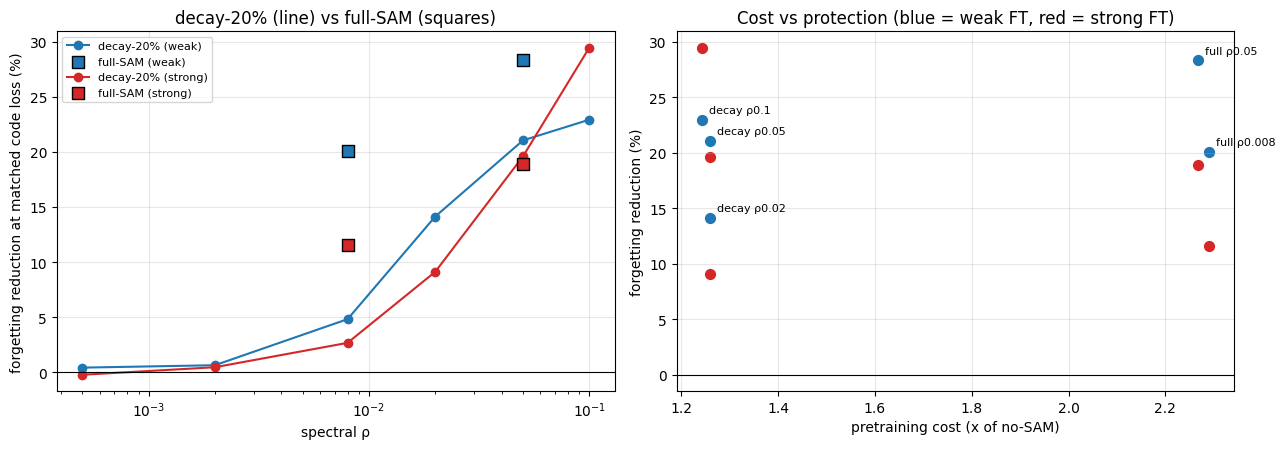

저장: /kaggle/working/exp_l7


In [7]:
# ============ 셀 7: 결과 — decay vs full 공정 비교 + ρ 축 전체 ============
import matplotlib.pyplot as plt
df = pd.DataFrame(ROWS)
TARGET = {}
df['matched_forgetting'] = np.nan
for st in ['weak', 'strong']:
    sub = df[df.strength == st]
    TARGET[st] = max(min(p['code'] for p in CURVES[f'{r.adam_lr}|{r.seed}|{r.pre}']) for r in sub.itertuples())
    for i, r in sub.iterrows():
        df.loc[i, 'matched_forgetting'] = baby_at(CURVES[f'{r.adam_lr}|{r.seed}|{r.pre}'], TARGET[st]) - r.baby_before
df.to_csv(f'{OUT}/ft_results_final.csv', index=False)

print('===== 1. 평균 =====')
display(df.groupby(['strength', 'pre'], sort=False)[['code_after', 'baby_before', 'baby_after', 'forgetting',
                                                    'matched_forgetting', 'delta_rel']].mean().round(4))

print('\n===== 2. pre_off_repro 대비 망각 감소 (같은 seed 짝 비교) =====')
EFF = []
for st in ['weak', 'strong']:
    print(f'\n[{st}]  같은 코드 loss 기준점 = {TARGET[st]:.3f}')
    a = df[(df.strength == st) & (df.pre == 'pre_off_repro')].set_index('seed').sort_index()
    print(f'  (재현 확인) off_repro 망각 {a.forgetting.mean():.4f}  vs  L6B 기록 {"1.0204" if st == "weak" else "1.7459"}')
    for pre in FT_MODELS[1:]:
        b = df[(df.strength == st) & (df.pre == pre)].set_index('seed').sort_index()
        d_m = a.matched_forgetting - b.matched_forgetting
        red_f = 1 - b.forgetting.mean() / a.forgetting.mean()
        red_m = 1 - b.matched_forgetting.mean() / a.matched_forgetting.mean()
        EFF.append(dict(strength=st, model=pre, cost=COST[pre], red_final=red_f, red_matched=red_m,
                        pos_matched=int((d_m > 0).sum()), code_gain=(a.code_after - b.code_after).mean()))
        print(f'  {pre:24s} 비용 {COST[pre]:.2f}배 | 최종 망각 {red_f*100:+5.1f}% | 같은 지점 {red_m*100:+5.1f}% '
              f'({int((d_m>0).sum())}/3) seed별 {[round(x, 4) for x in d_m]} | 코드 loss 차 {(a.code_after - b.code_after).mean():+.4f}')
eff7 = pd.DataFrame(EFF); eff7.to_csv(f'{OUT}/efficiency.csv', index=False)

l5 = pd.read_csv(find_input('exp_l5_finetune', 'efficiency.csv'))
l6 = pd.read_csv(find_input('exp_l6_finetune', 'efficiency.csv'))
def red(tab, st, model):
    r = tab[(tab.strength == st) & (tab.model == model)]
    return r.red_matched.item() if len(r) else float('nan')

dk, fk = NEW[0], NEW[1]
print('\n===== 3. 헤드라인: 같은 ρ 0.05에서 decay 20% vs full (같은 지점 망각 감소) =====')
for st in ['weak', 'strong']:
    d05, f05 = red(l6, st, 'pre_decay_spec_0.05'), red(eff7, st, fk)
    f008 = red(l5, st, 'pre_full_spec')
    print(f'  [{st}] decay ρ0.05 {d05*100:+.1f}% (비용 1.26배)  vs  full ρ0.05 {f05*100:+.1f}% (비용 {COST[fk]:.2f}배)'
          f'  → decay가 full의 {d05/f05*100:.0f}%   | 참고: full ρ0.008 {f008*100:+.1f}%')

print('\n===== 4. decay 20% 구간 ρ 축 전체 (같은 지점 망각 감소) =====')
RHO = {}
for st in ['weak', 'strong']:
    RHO[st] = {5e-4: red(l5, st, 'pre_decay_spec_0.0005'), 2e-3: red(l5, st, 'pre_decay_spec_0.002'),
               8e-3: red(l5, st, 'pre_decay_spec_0.008'), 0.02: red(l6, st, 'pre_decay_spec_0.02'),
               0.05: red(l6, st, 'pre_decay_spec_0.05'), CFG['decay_rho_new']: red(eff7, st, dk)}
    print(f'  [{st}] ' + ' | '.join(f'ρ {r:g}: {v*100:+.1f}%' for r, v in RHO[st].items()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for st, c in [('weak', 'tab:blue'), ('strong', 'tab:red')]:
    rs = sorted(RHO[st])
    axes[0].plot(rs, [RHO[st][r] * 100 for r in rs], '-o', color=c, label=f'decay-20% ({st})')
    axes[0].scatter([8e-3, CFG['full_rho_new']], [red(l5, st, 'pre_full_spec') * 100, red(eff7, st, fk) * 100],
                    marker='s', s=70, color=c, edgecolor='k', zorder=3, label=f'full-SAM ({st})')
axes[0].set_xscale('log'); axes[0].axhline(0, color='k', lw=0.8); axes[0].grid(alpha=0.3); axes[0].legend(fontsize=8)
axes[0].set_xlabel('spectral ρ'); axes[0].set_ylabel('forgetting reduction at matched code loss (%)')
axes[0].set_title('decay-20% (line) vs full-SAM (squares)')
pts = [('decay ρ0.02', 1.26, 'pre_decay_spec_0.02', l6), ('decay ρ0.05', 1.26, 'pre_decay_spec_0.05', l6),
       (f'decay ρ{CFG["decay_rho_new"]:g}', COST[dk], dk, eff7), ('full ρ0.008', 2.29, 'pre_full_spec', l5),
       (f'full ρ{CFG["full_rho_new"]:g}', COST[fk], fk, eff7)]
for st, c in [('weak', 'tab:blue'), ('strong', 'tab:red')]:
    for name, cost, model, tab in pts:
        v = red(tab, st, model) * 100
        axes[1].scatter(cost, v, color=c, s=50)
        if st == 'weak': axes[1].annotate(name, (cost, v), textcoords='offset points', xytext=(5, 5), fontsize=8)
axes[1].axhline(0, color='k', lw=0.8); axes[1].grid(alpha=0.3)
axes[1].set_xlabel('pretraining cost (x of no-SAM)'); axes[1].set_ylabel('forgetting reduction (%)')
axes[1].set_title('Cost vs protection (blue = weak FT, red = strong FT)')
plt.tight_layout(); plt.savefig(f'{OUT}/headline_decay_vs_full.png', dpi=150); plt.show()
json.dump(dict(targets=TARGET, efficiency=EFF, rho_axis=RHO, cost=COST), open(f'{OUT}/summary.json', 'w'), indent=2, default=float)
print('저장:', OUT)